In [1]:
import time
import numpy as np
from IPython.display import Markdown, display

from ifm_konwoledge_enginnering.Block_World.Project.src.World import World
from ifm_konwoledge_enginnering.Block_World.Project.src.search_path.bfs import bfs_with_stats
from ifm_konwoledge_enginnering.Block_World.Project.src.search_path.dfs import dfs_with_stats
from ifm_konwoledge_enginnering.Block_World.Project.src.utils.state_generator import start_goal_generator
from ifm_konwoledge_enginnering.Block_World.Project.src.utils.path_utils import check_path

DEFAULT_SEED = 42
BLOCK_COUNTS = range(3, 9)
MAX_EXPANDED = 10_000
EXTENDED_MOVES = True


In [2]:
def run_search(algorithm, search_fn, start, goal, n_blocks, seed=DEFAULT_SEED):
    """Run one search and return comparable metrics and its path."""
    wall_start = time.perf_counter()
    try:
        result = search_fn(
            start,
            goal,
            max_visited_notes=MAX_EXPANDED,
            extended=EXTENDED_MOVES,
        )
    except RuntimeError as error:
        return {
            "algorithm": algorithm,
            "blocks": n_blocks,
            "seed": seed,
            "status": f"limit / failure: {error}",
            "path_length": None,
            "expanded_nodes": f">={MAX_EXPANDED}",
            "time_seconds": time.perf_counter() - wall_start,
            "path": None,
        }

    # check_path validates the moves and leaves the resulting placement on this copy.
    current = World(start.placement.copy())
    valid_moves = check_path(current, result.path)
    valid = valid_moves and np.array_equal(current.placement, goal.placement)

    return {
        "algorithm": algorithm,
        "blocks": n_blocks,
        "seed": seed,
        "status": "valid" if valid else "INVALID PATH",
        "path_length": len(result.path),
        "expanded_nodes": result.expanded,
        "time_seconds": result.elapsed,
        "path": result.path,
    }

def show_result(result, show_path=False):
    print("=" * 48)
    print(f"{result['algorithm']} | blocks={result['blocks']} | seed={result['seed']}")
    print(f"Status: {result['status']}")
    print(f"Path length: {result['path_length']}")
    print(f"Expanded nodes: {result['expanded_nodes']}")
    print(f"Time: {result['time_seconds']:.6f} seconds")
    if show_path and result["path"] is not None:
        print("Moves are shown as (block moved, destination); 0 means table.")
        for move in result["path"]:
            print(f"({move.moving}, {move.destination})")

def display_table(records, columns):
    def format_value(value):
        if isinstance(value, float):
            return f"{value:.6f}"
        return str(value)

    header = "| " + " | ".join(columns) + " |"
    divider = "| " + " | ".join("---" for _ in columns) + " |"
    rows = [
        "| " + " | ".join(format_value(record[column]) for column in columns) + " |"
        for record in records
    ]
    display(Markdown("\n".join([header, divider, *rows])))


## Example: both algorithms on the same problem

The generator uses seed 42 by default. Both searches receive the same start and goal.

In [3]:
example_n = 4
example = start_goal_generator(example_n)
print(f"Start: {example.start.placement}")
print(f"Goal:  {example.goal.placement}")

example_results = [
    run_search("DFS", dfs_with_stats, example.start, example.goal, example_n),
    run_search("BFS", bfs_with_stats, example.start, example.goal, example_n),
]
for result in example_results:
    show_result(result, show_path=True)


Start: [0 3 4 0]
Goal:  [4 0 0 3]
DFS | blocks=4 | seed=42
Status: valid
Path length: 4
Expanded nodes: 15
Time: 0.009433 seconds
Moves are shown as (block moved, destination); 0 means table.
(2, 0)
(3, 0)
(4, 3)
(1, 4)
BFS | blocks=4 | seed=42
Status: valid
Path length: 4
Expanded nodes: 13
Time: 0.010022 seconds
Moves are shown as (block moved, destination); 0 means table.
(2, 0)
(3, 0)
(4, 3)
(1, 4)


## Paired comparison by block count

Each block count gets one reproducible start/goal pair (default seed 42); DFS and BFS solve that same pair. The expansion cap keeps BFS runs bounded. A capped run is marked as a limit/failure and is not counted as a completed path.

In [4]:
results = []
for n_blocks in BLOCK_COUNTS:
    problem = start_goal_generator(n_blocks)  # seed defaults to 42
    print(f"Running {n_blocks} blocks; start={problem.start.placement}, goal={problem.goal.placement}")
    results.append(run_search("DFS", dfs_with_stats, problem.start, problem.goal, n_blocks))
    results.append(run_search("BFS", bfs_with_stats, problem.start, problem.goal, n_blocks))

display_table(
    results,
    ["blocks", "seed", "algorithm", "status", "path_length", "expanded_nodes", "time_seconds"],
)


Running 3 blocks; start=[2 3 0], goal=[0 1 0]
Running 4 blocks; start=[0 3 4 0], goal=[4 0 0 3]
Running 5 blocks; start=[2 0 5 3 0], goal=[5 4 0 1 0]
Running 6 blocks; start=[2 5 4 0 6 0], goal=[6 5 1 0 0 0]
Running 7 blocks; start=[0 5 4 0 7 2 0], goal=[5 0 1 0 0 4 2]
Running 8 blocks; start=[6 0 5 0 0 2 8 3], goal=[6 4 5 3 0 0 8 2]


| blocks | seed | algorithm | status | path_length | expanded_nodes | time_seconds |
| --- | --- | --- | --- | --- | --- | --- |
| 3 | 42 | DFS | valid | 2 | 2 | 0.000833 |
| 3 | 42 | BFS | valid | 2 | 2 | 0.000424 |
| 4 | 42 | DFS | valid | 4 | 15 | 0.009644 |
| 4 | 42 | BFS | valid | 4 | 13 | 0.009991 |
| 5 | 42 | DFS | valid | 38 | 67 | 0.057877 |
| 5 | 42 | BFS | valid | 5 | 138 | 0.155649 |
| 6 | 42 | DFS | valid | 8 | 10 | 0.018238 |
| 6 | 42 | BFS | valid | 6 | 328 | 0.496930 |
| 7 | 42 | DFS | valid | 8 | 8 | 0.020588 |
| 7 | 42 | BFS | valid | 7 | 4742 | 9.178131 |
| 8 | 42 | DFS | valid | 22 | 22 | 0.075678 |
| 8 | 42 | BFS | limit / failure: Search limit exceeded: 10000 nodes expanded | None | >=10000 | 27.934435 |

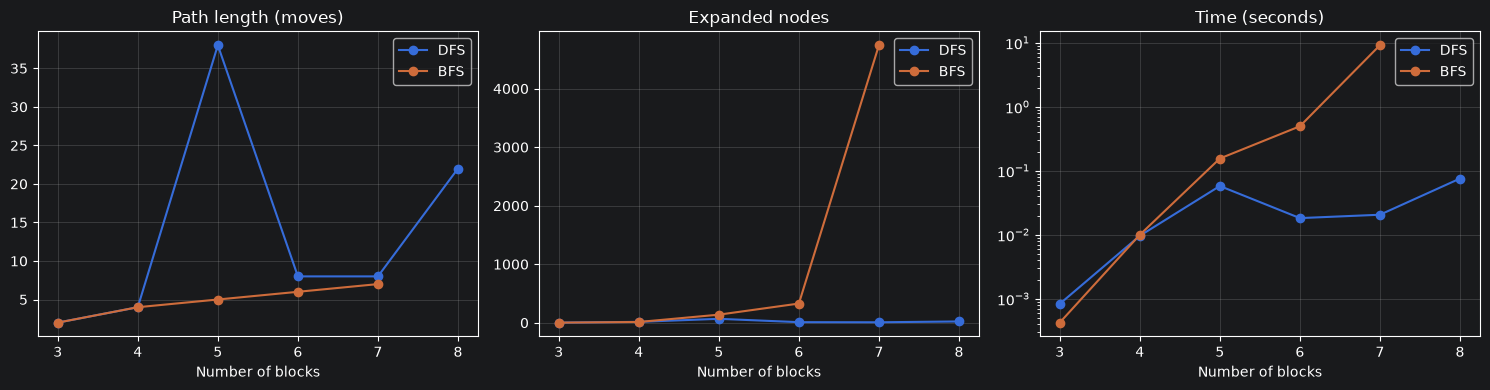

In [5]:
completed = [row for row in results if row["status"] == "valid"]
if not completed:
    print("No completed runs to plot.")
else:
    try:
        import matplotlib.pyplot as plt
    except ImportError:
        print("Install matplotlib to display comparison plots; the results table is still available.")
    else:
        metrics = [
            ("path_length", "Path length (moves)"),
            ("expanded_nodes", "Expanded nodes"),
            ("time_seconds", "Time (seconds)"),
        ]
        fig, axes = plt.subplots(1, 3, figsize=(15, 4))
        for axis, (metric, title) in zip(axes, metrics):
            for algorithm in ("DFS", "BFS"):
                selected = sorted(
                    (row for row in completed if row["algorithm"] == algorithm),
                    key=lambda row: row["blocks"],
                )
                axis.plot(
                    [row["blocks"] for row in selected],
                    [row[metric] for row in selected],
                    marker="o",
                    label=algorithm,
                )
            axis.set_title(title)
            axis.set_xlabel("Number of blocks")
            axis.grid(True, alpha=0.3)
            axis.legend()
        axes[2].set_yscale("log")
        fig.tight_layout()
        plt.show()


## Reading the results

Compare path length, expanded nodes, and elapsed search time for each matched problem. BFS should produce a shortest path for this unit-cost search; DFS may find a longer path. Timing is machine-dependent, while path validity and length are reproducible for the fixed inputs and move ordering. The expansion cap means a limited run has no path-length result.